In [15]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np


dti = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
dti = dti[dti.regionname == 'CST_R']
dti = dti[dti.isPatient == 1]

dti_week = [0,4]
dti = dti[(dti.regionname == 'CST_R') & (dti.Week.isin(dti_week))] # W0 FA as measure of integrity of affected CST
dti = dti.sort_values('Week').drop_duplicates(['subj_id', 'side'], keep = 'first').reset_index(drop = True) # keep only W0 (or W4 for those wihtout W0)

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0


# cerebellum GMV
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_Nettekoven_LeftRight_GM_mod.tsv'), sep = '\t')
cerebel = cerebel[cerebel.isPatient==1] # just patients

cerebel['hemisphere'] = cerebel.regionname.str[-1]
cerebel['regionname_bilat'] = cerebel.regionname.str[:-2]

cerebel_wide = cerebel.pivot(index = ['subj_id', 'Week', 'regionname_bilat'], columns = 'hemisphere', values = 'mean')
cerebel_wide['left_norm'] = cerebel_wide['L']/cerebel_wide['R']
cerebel_wide = cerebel_wide.reset_index()
cerebel = cerebel_wide.melt(
    id_vars = ['subj_id', 'Week', 'regionname_bilat'],
    value_vars = ['L', 'R', 'left_norm'],
    var_name = 'metric_cerebel', value_name = 'mean_cerebel'
)
cerebel = cerebel[cerebel.metric_cerebel == 'left_norm']
cerebel = cerebel.drop(columns = 'metric_cerebel')
cerebel = cerebel.rename(columns = {'mean_cerebel': 'left_norm'})


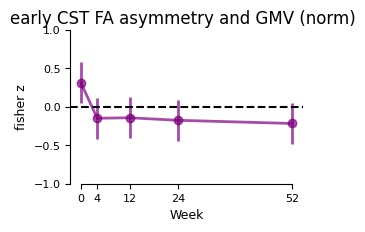

In [19]:
# FISHER Z TRANSFORM
rows_cerebel = []
for week in gl.weeks:
    cst_plot = dti
    cerebel_plot = cerebel[(cerebel.Week == week)]
    cerebel_cst = pd.merge(cerebel_plot, cst_plot, on = ['subj_id'], suffixes = ('_cerebel', '_cst'))
    
    r_stat, p_val = stats.pearsonr(cerebel_cst['asymmetry_index'], cerebel_cst['left_norm']) # use fitted value from piecewise function, y_hat

    n = len(cerebel_cst.subj_id.unique())
    z, se = np.arctanh(r_stat), 1/np.sqrt(n-3)
    lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
    rows_cerebel.append({'Week': week, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
rdf_cerebel = pd.DataFrame(rows_cerebel)

# plot r values for correlations

fig, ax = plt.subplots(figsize = (3,2))
ax.errorbar(x = rdf_cerebel['Week'], y = rdf_cerebel['z'], yerr = se,              
marker = 'o', linestyle = '-', linewidth = 2, color = 'purple', alpha = .7)

ax.set_xticks(gl.weeks)
ax.set_xlabel('Week')
ax.set_ylabel('fisher z')
plt.suptitle("early CST FA asymmetry and GMV (norm)")
ax.set_ylim(-1, 1)
plt.axhline(y = 0, linestyle = '--', color = 'k', linewidth = '1.5')
sns.despine(trim = True)
plt.show()